# Cycle 6 - Allègement du modèle pour la mise en production

Le modèle du cycle 5 occupe environ **950 Mo de RAM** une fois chargé par l'API (mesuré avec `docker stats`). Le fichier `.joblib` ne pèse que 182 Mo parce qu'il est compressé, mais il est entièrement décompressé en mémoire.

L'hébergeur visé (Render, offre gratuite) limite le service à **512 Mo de RAM**. Il faut donc un modèle plus léger.

Objectifs de ce cycle :
1. Mesurer la taille en mémoire du modèle du cycle 5.
2. Comparer quelques variantes plus légères de la Random Forest, en validation croisée temporelle sur le train (comme au cycle 4).
3. Retenir la meilleure variante qui respecte un budget mémoire, puis l'évaluer **une seule fois** sur le test, face au modèle du cycle 5.
4. Vérifier que les recommandations restent cohérentes, puis sauvegarder le nouveau modèle pour l'API.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import pickle
from datetime import datetime as dt
from pathlib import Path

import joblib
import mlflow
import numpy as np
import pandas as pd
import sklearn
from matplotlib import pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

import notebooks.utils as utils
# Import par le chemin complet "notebooks.<module>" : le modèle sauvegardé référence cette classe,
# l'API doit pouvoir la ré-importer depuis la racine du projet avec le même chemin.
from notebooks.agritech_feature_engineering import AgritechFeatureEngineering

In [3]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Agriculture_optimization")
mlflow.end_run()
mlflow.set_system_metrics_sampling_interval(1)

In [4]:
dataset = pd.read_csv('../data/rafined/dataset.csv', sep=',')
dataset.drop(columns=['Area ISO Code', 'Area ISO Alpha-2 Code', 'Area ISO Alpha-3 Code'], inplace=True)

## Données d'entrée du modèle

Mêmes colonnes et même découpage temporel que dans les cycles précédents.

In [5]:
RANDOM_STATE = 42
TARGET = 'hg/ha'

CATEGORICAL_FEATURES = ['Area', 'Item']
NUMERIC_INPUTS = [
    'avg_temp',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'pesticides_kg_ha',
    'missing_pesticide_value',
    'missing_rain_value',
    'missing_temp_value',
]
INPUT_FEATURES = CATEGORICAL_FEATURES + NUMERIC_INPUTS

X_train, X_test, y_train, y_test = utils.test_train_time_split(dataset)
X_train = X_train.sort_values('Year')  # indispensable pour TimeSeriesSplit
y_train = y_train.loc[X_train.index]
split_year = int(X_test['Year'].min())

X_train, X_test = X_train[INPUT_FEATURES], X_test[INPUT_FEATURES]

Année de césure calculée : 2009
Proportion réelle train : 78.73% (20349 lignes)
Proportion réelle test  : 21.27% (5499 lignes)


## Pipeline et mesure de la taille

Le pipeline est identique au cycle 5. Seuls les hyperparamètres de la Random Forest changent, d'où le paramètre `params` de `build_model`.

Pour mesurer la place d'un modèle en RAM, on le sérialise **sans compression** : la taille obtenue est une bonne approximation de sa taille en mémoire.

In [6]:
# Hyperparamètres du cycle 5 (issus de l'optimisation du cycle 4) : notre référence
REFERENCE_PARAMS = {
    'n_estimators': 200,
    'max_features': 0.5,
    'max_depth': 40,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'bootstrap': False,
}


def build_model(params):
    """Construit le pipeline complet : feature engineering, prétraitement, Random Forest sur cible log1p."""
    numeric_features = NUMERIC_INPUTS + ['aridity', 'avg_temp_square']  # 2 variables créées par AgritechFeatureEngineering

    preprocessor = ColumnTransformer(
        transformers=[
            ('area_encoding',
             TargetEncoder(target_type='continuous', cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)),
             ['Area']),
            ('item_encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Item']),
            ('num_pipeline', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
            ]), numeric_features),
        ],
        remainder='drop'
    )

    pipeline = Pipeline([
        ('features', AgritechFeatureEngineering()),
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)),
    ])

    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)


def model_size_mb(model):
    """Taille du modèle sérialisé sans compression (≈ place occupée en RAM), en Mo."""
    return len(pickle.dumps(model)) / 1e6

## Variantes plus légères

Avec `bootstrap=False`, `min_samples_leaf=1` et `max_depth=40`, chaque arbre apprend tout le jeu d'entraînement, presque jusqu'à une feuille par ligne : le nombre de nœuds explose. Trois leviers permettent de l'alléger :
- **`n_estimators`** : moins d'arbres. Passer de 200 à 100 divise la taille par deux.
- **`min_samples_leaf`** : chaque feuille doit regrouper plusieurs lignes, ce qui réduit fortement le nombre de nœuds.
- **`max_depth`** : limite la profondeur des arbres.

Les autres hyperparamètres restent ceux du cycle 5.

In [7]:
REFERENCE = 'Cycle 5 (référence)'

CANDIDATES = {
    REFERENCE: REFERENCE_PARAMS,
    '100 arbres': {**REFERENCE_PARAMS, 'n_estimators': 100},
    '100 arbres, feuilles ≥ 2': {**REFERENCE_PARAMS, 'n_estimators': 100, 'min_samples_leaf': 2},
    '100 arbres, feuilles ≥ 5': {**REFERENCE_PARAMS, 'n_estimators': 100, 'min_samples_leaf': 5},
    '100 arbres, feuilles ≥ 5, profondeur 20': {**REFERENCE_PARAMS, 'n_estimators': 100, 'min_samples_leaf': 5, 'max_depth': 20},
    '100 arbres, feuilles ≥ 10, profondeur 20': {**REFERENCE_PARAMS, 'n_estimators': 100, 'min_samples_leaf': 10, 'max_depth': 20},
}

## Comparaison en validation croisée temporelle

Comme au cycle 4, les performances sont mesurées par `TimeSeriesSplit` (5 plis) **sur le train uniquement** : le test reste intact pour l'évaluation finale.

La taille est mesurée sur le modèle entraîné sur tout le train. Le modèle de production, entraîné sur toutes les années, sera un peu plus gros : on le mesurera à nouveau avant de le sauvegarder.

⏱️ Cette cellule prend plusieurs minutes (6 variantes × 6 entraînements).

In [8]:
scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

rows = []
for name, params in CANDIDATES.items():
    model = build_model(params)
    cv_results = cross_validate(model, X_train, y_train, cv=TimeSeriesSplit(5), scoring=scoring)
    model.fit(X_train, y_train)

    rows.append({
        'candidat': name,
        'taille_mo': model_size_mb(model),
        'cv_r2': cv_results['test_r2'].mean(),
        'cv_mae': -cv_results['test_mae'].mean(),
        'cv_rmse': -cv_results['test_rmse'].mean(),
    })
    print(f"{name} : {rows[-1]['taille_mo']:.0f} Mo, RMSE CV = {rows[-1]['cv_rmse']:.0f}")

results = pd.DataFrame(rows).set_index('candidat')
results['evolution_taille_%'] = (results['taille_mo'] / results.loc[REFERENCE, 'taille_mo'] - 1) * 100
results['evolution_rmse_%'] = (results['cv_rmse'] / results.loc[REFERENCE, 'cv_rmse'] - 1) * 100
results.round(2)

Cycle 5 (référence) : 566 Mo, RMSE CV = 24976
100 arbres : 283 Mo, RMSE CV = 24976
100 arbres, feuilles ≥ 2 : 124 Mo, RMSE CV = 25087
100 arbres, feuilles ≥ 5 : 46 Mo, RMSE CV = 26148
100 arbres, feuilles ≥ 5, profondeur 20 : 41 Mo, RMSE CV = 26319
100 arbres, feuilles ≥ 10, profondeur 20 : 21 Mo, RMSE CV = 28561


,taille_mo,cv_r2,cv_mae,cv_rmse,evolution_taille_%,evolution_rmse_%
candidat,,,,,,
Cycle 5 (référence),566.31,0.88,12632.35,24976.17,0.00,0.00
100 arbres,283.14,0.88,12664.93,24975.83,-50.00,-0.00
"100 arbres, feuilles ≥ 2",124.21,0.88,12817.67,25086.97,-78.07,0.44
"100 arbres, feuilles ≥ 5",46.33,0.87,13794.56,26148.10,-91.82,4.69
"100 arbres, feuilles ≥ 5, profondeur 20",40.94,0.87,13873.47,26319.33,-92.77,5.38
"100 arbres, feuilles ≥ 10, profondeur 20",21.08,0.84,15413.82,28561.26,-96.28,14.35


## Choix du modèle

**Budget mémoire : 250 Mo pour le modèle.** Avec Python, pandas, scikit-learn et FastAPI (environ 150 Mo), l'API reste ainsi nettement sous les 512 Mo de Render.

Règle de choix : parmi les variantes qui respectent le budget, on retient celle qui a la meilleure RMSE en validation croisée.

Variante retenue : 100 arbres, feuilles ≥ 2
{'n_estimators': 100, 'max_features': 0.5, 'max_depth': 40, 'min_samples_split': 2, 'min_samples_leaf': 2, 'bootstrap': False}


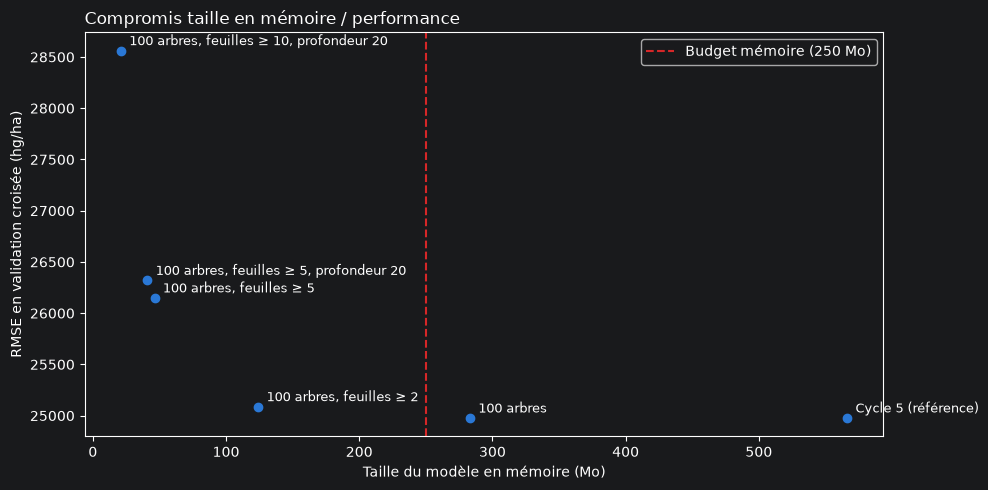

In [9]:
MAX_SIZE_MB = 250

eligibles = results[results['taille_mo'] <= MAX_SIZE_MB]
assert not eligibles.empty, "Aucune variante ne respecte le budget : ajouter des variantes plus légères."

CHOSEN = eligibles['cv_rmse'].idxmin()
CHOSEN_PARAMS = CANDIDATES[CHOSEN]
print(f"Variante retenue : {CHOSEN}")
print(CHOSEN_PARAMS)

# Compromis taille / performance
fig_compromis, ax = plt.subplots(figsize=(10, 5))
ax.scatter(results['taille_mo'], results['cv_rmse'], color='#2a78d6')
for name, row in results.iterrows():
    ax.annotate(name, (row['taille_mo'], row['cv_rmse']), xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.axvline(MAX_SIZE_MB, color='#d62728', linestyle='--', label=f'Budget mémoire ({MAX_SIZE_MB} Mo)')
ax.set_title("Compromis taille en mémoire / performance", loc='left')
ax.set_xlabel("Taille du modèle en mémoire (Mo)")
ax.set_ylabel("RMSE en validation croisée (hg/ha)")
ax.legend()
fig_compromis.tight_layout()
plt.show()

## Évaluation finale sur le jeu de test (2009 à 2013)

Le modèle retenu est évalué une seule fois sur le test, face au modèle du cycle 5 et à la baseline naïve (médiane pays × culture), avec les mêmes indicateurs qu'au cycle 5.

In [10]:
def precision_15pct(y_true, y_pred):
    """Part des prédictions à ±15 % du rendement réel."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(np.abs(y_pred - y_true) <= 0.15 * y_true))


def test_evaluation(y_pred):
    metrics = utils.evaluate(y_test, y_pred)
    metrics['precision_15pct'] = precision_15pct(y_test, y_pred)
    return metrics


reference_model = build_model(REFERENCE_PARAMS).fit(X_train, y_train)
light_model = build_model(CHOSEN_PARAMS).fit(X_train, y_train)

reference_metrics = test_evaluation(reference_model.predict(X_test))
test_metrics = test_evaluation(light_model.predict(X_test))

# Baseline naïve sur les mêmes années : médiane historique du couple (pays, culture)
train_df = X_train.assign(**{TARGET: y_train})
mediane_pays_culture = train_df.groupby(['Area', 'Item'])[TARGET].median()
mediane_culture = train_df.groupby('Item')[TARGET].median()
pred_baseline = X_test.join(mediane_pays_culture.rename('pred'), on=['Area', 'Item'])['pred']
pred_baseline = pred_baseline.fillna(X_test['Item'].map(mediane_culture))
baseline_metrics = test_evaluation(pred_baseline)

comparaison_test = pd.DataFrame({
    'Baseline naïve': baseline_metrics,
    REFERENCE: reference_metrics,
    f'Cycle 6 ({CHOSEN})': test_metrics,
}).T[['r2', 'mae', 'rmse', 'precision_15pct']]
comparaison_test['taille_mo'] = [np.nan, model_size_mb(reference_model), model_size_mb(light_model)]
comparaison_test.round(3)

,r2,mae,rmse,precision_15pct,taille_mo
Baseline naïve,0.836,16461.082,32645.915,0.479,NaN
Cycle 5 (référence),0.852,15808.246,31012.026,0.485,566.306
"Cycle 6 (100 arbres, feuilles ≥ 2)",0.854,15886.098,30871.320,0.476,124.205


## Les recommandations changent-elles ?

Pour le métier, l'important est que le classement des cultures (endpoint `/recommend`) reste le même. On compare les deux modèles sur les contextes réels de trois pays en 2013.

In [11]:
CULTURES = sorted(dataset['Item'].unique())


def ranking(model, area, year=2013):
    """Cultures classées par rendement prédit décroissant, pour le contexte réel d'un pays une année donnée."""
    context = dataset[(dataset['Area'] == area) & (dataset['Year'] == year)].iloc[0][INPUT_FEATURES].to_dict()
    rows = pd.DataFrame([{**context, 'Item': item} for item in CULTURES])[INPUT_FEATURES]
    predictions = pd.Series(model.predict(rows), index=CULTURES)
    return list(predictions.sort_values(ascending=False).index)


comparaison_reco = []
for pays in ['France', 'India', 'Kenya']:
    classement_reference = ranking(reference_model, pays)
    classement_allege = ranking(light_model, pays)
    comparaison_reco.append({
        'pays': pays,
        'top 3 cycle 5': ', '.join(classement_reference[:3]),
        'top 3 cycle 6': ', '.join(classement_allege[:3]),
        'même culture n°1': classement_reference[0] == classement_allege[0],
        'même classement complet': classement_reference == classement_allege,
    })

comparaison_reco = pd.DataFrame(comparaison_reco)
comparaison_reco

,pays,top 3 cycle 5,top 3 cycle 6,même culture n°1,même classement complet
0,France,"Pomme de terre, Igname, Plantains et autres","Pomme de terre, Patate douce, Igname",True,False
1,India,"Manioc, Pomme de terre, Plantains et autres","Manioc, Pomme de terre, Plantains et autres",True,True
2,Kenya,"Pomme de terre, Plantains et autres, Patate douce","Pomme de terre, Plantains et autres, Patate douce",True,True


In [12]:
# Le modèle de référence n'est plus utile : on libère la mémoire avant l'entraînement final
del reference_model

## Modèle de production : réentraînement sur toutes les données

Comme au cycle 5 : le modèle retenu est réentraîné sur toutes les années (1990 à 2013) pour l'API. Les performances annoncées restent celles mesurées sur le test ci-dessus.

In [13]:
X_all = dataset[INPUT_FEATURES]
y_all = dataset[TARGET]

final_model = build_model(CHOSEN_PARAMS).fit(X_all, y_all)

final_size_mb = model_size_mb(final_model)
print(f"Taille en mémoire du modèle de production : {final_size_mb:.0f} Mo (budget : {MAX_SIZE_MB} Mo)")

Taille en mémoire du modèle de production : 158 Mo (budget : 250 Mo)


## Sauvegarde pour l'API

Mêmes fichiers et même format de métadonnées qu'au cycle 5 : l'API n'a pas besoin d'être modifiée.

In [14]:
models_dir = Path('..').resolve() / 'models'
model_path = models_dir / 'agriculture_model.joblib'
metadata_path = models_dir / 'agriculture_model_metadata.json'

version = dt.now().strftime("%Y%m%d_%H%M%S")

metadata = {
    'version': version,
    'created_at': dt.now().isoformat(timespec='seconds'),
    'sklearn_version': sklearn.__version__,
    'model': 'RandomForestRegressor allégé (cible log1p)',
    'hyperparameters': CHOSEN_PARAMS,
    'random_state': RANDOM_STATE,
    'memory_size_mb': round(final_size_mb, 1),
    'target': TARGET,
    'target_unit': 'hectogrammes par hectare (hg/ha) ; 10 000 hg/ha = 1 t/ha',
    'input_features': INPUT_FEATURES,
    'input_dtypes': {c: str(X_all[c].dtype) for c in INPUT_FEATURES},
    'optional_features': [c for c in NUMERIC_INPUTS if not c.startswith('missing_')],
    'cultures': CULTURES,
    'pays': sorted(dataset['Area'].unique()),
    # Bornes observées des variables numériques (utilisées par le dashboard pour les sliders)
    'feature_ranges': {
        c: {
            'min': round(float(dataset[c].min()), 2),
            'median': round(float(dataset[c].median()), 2),
            'max': round(float(dataset[c].max()), 2),
        }
        for c in NUMERIC_INPUTS if not c.startswith('missing_')
    },
    'training_years': [int(dataset['Year'].min()), int(dataset['Year'].max())],
    'evaluation': {
        'methode': f"entraîné sur {int(dataset['Year'].min())}-{split_year - 1}, évalué sur {split_year}-{int(dataset['Year'].max())}",
        'modele': {k: round(float(v), 4) for k, v in test_metrics.items()},
        'baseline_mediane_pays_culture': {k: round(float(v), 4) for k, v in baseline_metrics.items()},
    },
}

# compress=3 : fichier plus léger sur disque (et moins de trafic Git LFS), sans effet sur la RAM
joblib.dump(final_model, model_path, compress=3)
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"Modèle enregistré : {model_path} ({model_path.stat().st_size / 1e6:.1f} Mo sur disque)")
print(f"Métadonnées enregistrées : {metadata_path}")

Modèle enregistré : /Users/auncly/Documents/Formation data scientist/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/models/agriculture_model.joblib (48.5 Mo sur disque)
Métadonnées enregistrées : /Users/auncly/Documents/Formation data scientist/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/models/agriculture_model_metadata.json


In [15]:
# Vérification : le modèle rechargé donne exactement les mêmes prédictions
reloaded = joblib.load(model_path)
sample = X_all.sample(5, random_state=RANDOM_STATE)
assert np.allclose(reloaded.predict(sample), final_model.predict(sample))

# Exemple d'appel tel que l'API le fera : une ligne, avec une valeur manquante
exemple_api = pd.DataFrame([{
    'Area': 'France', 'Item': 'Blé',
    'avg_temp': 12.5, 'average_rain_fall_mm_per_year': 867.0,
    'pesticides_tonnes': None, 'pesticides_kg_ha': None,
    'missing_pesticide_value': 1, 'missing_rain_value': 0, 'missing_temp_value': 0,
}])[INPUT_FEATURES]
print(f"Rendement prédit pour le blé en France : {reloaded.predict(exemple_api)[0]:.0f} hg/ha")

Rendement prédit pour le blé en France : 40590 hg/ha


## Enregistrement dans MLflow

In [16]:
with mlflow.start_run(run_name="Cycle 6 - Allègement du modèle", log_system_metrics=True):

    mlflow.set_tags({
        'date': dt.now().strftime("%Y-%m-%d"),
        'cycle': '6_allegement',
        'model_type': 'random_forest',
        'model_version': version,
        'mlflow.note.content': (
            f"Allègement du modèle du cycle 5 pour tenir dans {MAX_SIZE_MB} Mo de RAM (hébergement Render, 512 Mo). "
            f"Variantes comparées en validation croisée temporelle sur le train, variante retenue : {CHOSEN}. "
            "Évaluée une seule fois sur le test, face au cycle 5. Le modèle sauvegardé est réentraîné sur toutes les années."
        ),
    })

    mlflow.log_params({
        'split': 'temporel',
        'split_year': split_year,
        'model': 'RandomForestRegressor',
        'target_transform': 'log1p',
        'features': ', '.join(INPUT_FEATURES),
        'random_state': RANDOM_STATE,
        'max_size_mb': MAX_SIZE_MB,
        'variante_retenue': CHOSEN,
        **{f'model__{k}': v for k, v in CHOSEN_PARAMS.items()},
    })

    mlflow.log_metrics({
        **{f'test_{k}': v for k, v in test_metrics.items()},
        **{f'reference_test_{k}': v for k, v in reference_metrics.items()},
        **{f'baseline_test_{k}': v for k, v in baseline_metrics.items()},
        'model_size_mb': final_size_mb,
        'reference_size_mb': results.loc[REFERENCE, 'taille_mo'],
    })

    mlflow.log_figure(fig_compromis, 'compromis_taille_performance.png')
    mlflow.log_table(results.reset_index(), artifact_file='comparaison_variantes.json')
    mlflow.log_table(comparaison_reco, artifact_file='comparaison_recommandations.json')
    mlflow.log_artifact(str(model_path), artifact_path='modele')
    mlflow.log_artifact(str(metadata_path), artifact_path='modele')

2026/11/17 09:38:14 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/17 09:38:14 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/17 09:38:14 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/17 09:38:14 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run Cycle 6 - Allègement du modèle at: http://127.0.0.1:5000/#/experiments/1/runs/a9a513e2bd1342bcbbd6187f51d99915
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
